In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# 출력 구조화 

from pydantic import BaseModel, Field
from langchain.chat_models import init_chat_model

# 1) 스키마 정의
class SearchQuery(BaseModel):
    search_query: str = Field(..., description="웹 검색에 최적화된 질의문")
    justification: str = Field(..., description="해당 질의가 왜 적절한지의 근거")

# 2) 구조화된 출력으로 LLM 래핑
llm = init_chat_model("openai:gpt-4.1")
structured_llm = llm.with_structured_output(SearchQuery)

# 3) 프롬프트 실행
prompt = "랭그래프가 왜 필요한가?"
result = structured_llm.invoke(prompt)

# 4) 사용
print("검색어:", result.search_query)
print("근거:", result.justification)

검색어: 랭그래프 필요성
근거: 사용자가 랭그래프가 왜 필요한지, 즉 랭그래프의 필요성과 목적에 대해 질문하였으므로, 이에 대한 정보 및 이유를 찾기 위해 검색이 필요하다.


In [3]:
# 도구 호출

# 1) 도구 정의
def multiply(a: int, b: int) -> int:
    """두 수의 곱을 반환"""
    return a * b

# 2) LLM에 도구 바인딩
agent = llm.bind_tools([multiply])

# 3) 사용자 질문
user_msg = "2 곱하기 3은?"

# 4) 1차 LLM 호출 -> 도구 호출 의도 파악
msg = agent.invoke(user_msg)

# 5) tool_calls 확인 및 실행
results = {}
print(msg.tool_calls)

for call in getattr(msg, "tool_calls", []):
    name = call["name"]
    args = call["args"]
    if name == "multiply":
        results[name] = multiply(**args)
print(results)

[{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'call_UymuGxRzfA577Z3Vyc4LMZnR', 'type': 'tool_call'}]
{'multiply': 6}


In [4]:
# 프롬프트 체이닝 

from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    final_joke: str

In [5]:
# 1) 농담 생성
def generate_joke(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 짧은 농담을 작성해 주세요.")
    return {"joke": msg.content}

# 2) 품질 검사(펀치라인 확인)
def check_punchline(state: State):
    if "?" in state["joke"] or "!" in state["joke"]:
        return "Pass"
    return "Fail"

# 3) 농담 개선
def improve_joke(state: State):
    msg = llm.invoke(f"다음 농담에 말장난을 넣어 더 재미있게 만들어 주세요: {state['joke']}")
    return {"improved_joke": msg.content}

# 4) 농담 다듬기
def polish_joke(state: State):
    msg = llm.invoke(f"다음 농담에 예상치 못한 반전을 추가해 주세요: {state['improved_joke']}")
    return {"final_joke": msg.content}

In [6]:
workflow = StateGraph(State)

# 노드 등록
workflow.add_node("generate_joke", generate_joke)
workflow.add_node("improve_joke", improve_joke)
workflow.add_node("polish_joke", polish_joke)

# 순서 연결
workflow.add_edge(START, "generate_joke")
workflow.add_conditional_edges(
    "generate_joke", check_punchline, {"Fail": "improve_joke", "Pass": END}
)
workflow.add_edge("improve_joke", "polish_joke")
workflow.add_edge("polish_joke", END)

# 워크플로 컴파일
chain = workflow.compile()

In [7]:
state = chain.invoke({"topic": "한국"})

print("Initial joke:")
print(state["joke"])
print("\n--- --- ---\n")

if "improved_joke" in state:
    print("Improved joke:")
    print(state["improved_joke"])
    print("\n--- --- ---\n")

    print("Final joke:")
    print(state["final_joke"])
else:
    print("농담이 품질 검사를 통과하여 개선이 필요하지 않습니다!")

Initial joke:
물론이죠!  
왜 한국에서는 빨리빨리 문화가 발달했을까요?  
  
너무 맛있는 음식이 있어서 참을 수가 없거든요!

--- --- ---

농담이 품질 검사를 통과하여 개선이 필요하지 않습니다!


In [8]:
# 병렬 처리

# 상태 정의
class State(TypedDict):
    topic: str
    joke: str
    story: str
    poem: str
    combined_output: str


# 1) 농담 생성
def call_llm_1(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 농담을 작성해 주세요.")
    return {"joke": msg.content}

# 2) 이야기 생성
def call_llm_2(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 이야기를 짧게 작성해 주세요.")
    return {"story": msg.content}

# 3) 시 생성
def call_llm_3(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 시를 작성해 주세요.")
    return {"poem": msg.content}

# 4) 결과 합치기
def aggregator(state: State):
    combined = f"{state['topic']}에 관한 이야기, 농담, 시입니다!\n\n"
    combined += f"이야기:\n{state['story']}\n\n"
    combined += f"농담:\n{state['joke']}\n\n"
    combined += f"시:\n{state['poem']}"
    return {"combined_output": combined}

In [9]:
parallel_builder = StateGraph(State)

# 노드 등록
parallel_builder.add_node("call_llm_1", call_llm_1)
parallel_builder.add_node("call_llm_2", call_llm_2)
parallel_builder.add_node("call_llm_3", call_llm_3)
parallel_builder.add_node("aggregator", aggregator)

# 병렬 연결
parallel_builder.add_edge(START, "call_llm_1")
parallel_builder.add_edge(START, "call_llm_2")
parallel_builder.add_edge(START, "call_llm_3")

# 결과 합치기
parallel_builder.add_edge("call_llm_1", "aggregator")
parallel_builder.add_edge("call_llm_2", "aggregator")
parallel_builder.add_edge("call_llm_3", "aggregator")
parallel_builder.add_edge("aggregator", END)

# 컴파일
parallel_workflow = parallel_builder.compile()

In [10]:
state = parallel_workflow.invoke({"topic": "한국"})
print(state["combined_output"])

한국에 관한 이야기, 농담, 시입니다!

이야기:
한국은 동아시아에 위치한 나라로, 한반도의 남쪽에 자리하고 있습니다. 수도는 서울이며, 첨단기술과 문화, 전통이 조화를 이루는 곳입니다. K-팝, 한식, 한류 드라마로 세계적으로 유명하며, 역사적으로도 오랜 전통과 다양한 유산을 가지고 있습니다.

농담:
물론이죠! 가볍고 유쾌한 농담 하나 드릴게요.

---

한국 사람이 가장 좋아하는 동물은 뭘까요?

정답: 호랑이! (호랑이 기운이 솟아나니까요!)

---

더 필요하시다면 말씀해 주세요!

시:
물론입니다. 한국에 대한 시를 준비해 드리겠습니다.

---

**한반도의 노래**

바람이 불고, 한강이 흐른다  
산과 바다가 품은 푸른 고요 위에  
오랜 시간 쌓인 이야기,  
조심스레 새긴 이름 ‘한국’이 빛난다.

벚꽃 흩날리는 봄이면  
어린아인 듯 웃으며  
들녘을 달리던 기억들이  
여름 비에 씻겨나 듯 투명하다.

참새가 지저귀는 골목,  
김치의 매운 숨결,  
뜨거운 국물이 속을 데우는  
우리의 작은 방, 그 안식처.

고요한 새벽,  
종소리 울릴 때마다  
흔들렸던 역사마저  
다시 일어나 걸어가는 강인한 발걸음.

한류의 물결이 세상을 적실 때,  
전통과 오늘이 손을 잡는다.  
우리의 노래, 우리만의 춤  
자부심으로 피어나는 아름다움.

마음 속 깊은 곳,  
그리움이 출렁이는 나라  
언제나 돌아가고 싶은  
나의 뿌리, 나의 한국.

---


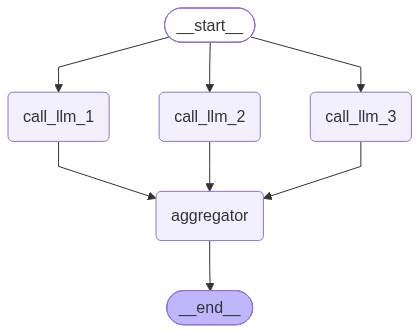

In [11]:
from IPython.display import Image, display

# 다이어그램 출력
display(Image(parallel_workflow.get_graph().draw_mermaid_png()))

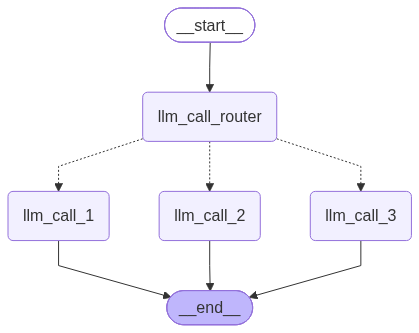

왜 한국에서는 자기 전에 스마트폰을 꼭 확인할까요?

혹시 BTS가 새 앨범 냈을까 봐!


In [12]:
# 라우팅

from typing_extensions import Literal
from langchain_core.messages import HumanMessage, SystemMessage

# 1) 라우팅 결정을 위한 구조화 출력 스키마
class Route(BaseModel):
    step: Literal["poem", "story", "joke"] = Field(
        None, description="라우팅의 다음 단계"
    )

# 2) 구조화 출력으로 동작하는 라우터 LLM
router = llm.with_structured_output(Route)

# 3) 상태 정의
class State(TypedDict):
    input: str
    decision: str
    output: str

# 4) 노드 정의 (각각 전용 프롬프트 사용)
def llm_call_1(state: State):
    """이야기 작성"""
    result = llm.invoke(f"다음 주제로 짧은 이야기를 작성해 주세요: {state['input']}")
    return {"output": result.content}

def llm_call_2(state: State):
    """농담 작성"""
    result = llm.invoke(f"다음 주제로 짧은 농담을 작성해 주세요: {state['input']}")
    return {"output": result.content}

def llm_call_3(state: State):
    """시 작성"""
    result = llm.invoke(f"다음 주제로 짧은 시를 작성해 주세요: {state['input']}")
    return {"output": result.content}

def llm_call_router(state: State):
    """입력을 적절한 노드로 라우팅"""
    decision = router.invoke(
        [
            SystemMessage(
                content="사용자 요청을 이야기(story), 농담(joke), 시(poem) 중 하나로 분류하고, "
                        "가장 알맞은 항목을 step에 지정하세요."
            ),
            HumanMessage(content=state["input"]),
        ]
    )
    return {"decision": decision.step}

# 5) 조건부 엣지에서 분기 로직
def route_decision(state: State):
    if state["decision"] == "story":
        return "llm_call_1"
    elif state["decision"] == "joke":
        return "llm_call_2"
    elif state["decision"] == "poem":
        return "llm_call_3"

# 6) 워크플로 구성
router_builder = StateGraph(State)
router_builder.add_node("llm_call_1", llm_call_1)
router_builder.add_node("llm_call_2", llm_call_2)
router_builder.add_node("llm_call_3", llm_call_3)
router_builder.add_node("llm_call_router", llm_call_router)

router_builder.add_edge(START, "llm_call_router")
router_builder.add_conditional_edges(
    "llm_call_router",
    route_decision,
    {
        "llm_call_1": "llm_call_1",
        "llm_call_2": "llm_call_2",
        "llm_call_3": "llm_call_3",
    },
)
router_builder.add_edge("llm_call_1", END)
router_builder.add_edge("llm_call_2", END)
router_builder.add_edge("llm_call_3", END)

router_workflow = router_builder.compile()

# 7) 다이어그램 확인
display(Image(router_workflow.get_graph().draw_mermaid_png()))

# 8) 실행
state = router_workflow.invoke({"input": "한국에 대한 농담을 써 주세요"})
print(state["output"])

In [13]:
# 오케스트레이터-워커 

from typing import Annotated, List
from langgraph.types import Send
import operator

# 보고서 섹션(Section) 정의
class Section(BaseModel):
    name: str = Field(description="이 보고서 섹션의 제목")
    description: str = Field(description="이 섹션에서 다룰 주요 주제와 개념에 대한 간략한 설명")

# 보고서 섹션 목록 구조
class Sections(BaseModel):
    sections: List[Section] = Field(description="보고서의 각 섹션 목록")

# LLM에 구조화 출력(Structured Output) 스키마를 적용
planner = llm.with_structured_output(Sections)

# 전체 워크플로 상태
class State(TypedDict):
    topic: str  # 보고서 주제
    sections: list[Section]  # 보고서 섹션 목록
    completed_sections: Annotated[list, operator.add]  # 모든 워커가 작성한 섹션 결과 모음
    final_report: str  # 최종 보고서

# 워커 상태
class WorkerState(TypedDict):
    section: Section
    completed_sections: Annotated[list, operator.add]

In [14]:
def orchestrator(state: State):
    """보고서 목차를 생성하는 오케스트레이터"""

    report_sections = planner.invoke([
        SystemMessage(content="보고서 목차를 생성해 주세요."),
        HumanMessage(content=f"보고서 주제: {state['topic']}"),
    ])
    return {"sections": report_sections.sections}

In [15]:
def llm_call(state: WorkerState):
    """각 보고서 섹션을 작성하는 워커"""

    section = llm.invoke([
        SystemMessage(content="제공된 제목과 설명에 따라 보고서 섹션을 작성하세요. 각 섹션에 머리말은 포함하지 말고, 마크다운 형식을 사용하세요."),
        HumanMessage(content=f"섹션 제목: {state['section'].name}\n설명: {state['section'].description}"),
    ])

    return {"completed_sections": [section.content]}

In [16]:
def synthesizer(state: State):
    """작성된 섹션들을 종합하여 최종 보고서 생성"""

    completed_sections = state["completed_sections"]
    combined_report = "\n\n---\n\n".join(completed_sections)
    return {"final_report": combined_report}

In [17]:
def assign_workers(state: State):
    """각 섹션에 워커 할당"""
    return [Send("llm_call", {"section": s}) for s in state["sections"]]

In [18]:
# 워크플로 빌더 생성
builder = StateGraph(State)

# 노드 등록
builder.add_node("orchestrator", orchestrator)
builder.add_node("llm_call", llm_call)
builder.add_node("synthesizer", synthesizer)

# 엣지 연결
builder.add_edge(START, "orchestrator")
builder.add_conditional_edges("orchestrator", assign_workers, ["llm_call"])
builder.add_edge("llm_call", "synthesizer")
builder.add_edge("synthesizer", END)

# 컴파일
orchestrator_worker = builder.compile()

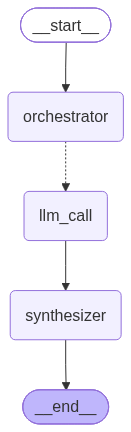

이번 보고서는 랭그래프 오케스트레이션(Langgraph Orchestration) 및 워커 법칙(Worker Law)에 대한 이해를 돕고, 이들 개념이 실제 적용되는 맥락과 그 의의를 설명하는 것을 목적으로 합니다. 최근 인공지능 및 워크플로우 자동화 분야에서 복잡한 프로세스의 효율적 관리를 위한 오케스트레이션 기술의 중요성이 높아지고 있습니다. 랭그래프 오케스트레이션은 다양한 시스템과 구성요소들이 유기적으로 상호작용하며, 복잡한 작업을 체계적으로 수행할 수 있도록 지원하는 기술적 프레임워크입니다. 아울러, 워커 법칙은 분산 시스템에서 개별 작업자(worker)들이 자원을 어떻게 효과적으로 사용할 수 있는지에 대한 원칙을 제시하여, 전체적인 운영 효율성 제고에 기여합니다. 본 보고서는 이러한 두 가지 핵심 개념이 현대 정보기술 환경에서 어떻게 통합적으로 활용되고 있는지에 대해 폭넓게 조망할 것입니다.

---

랭그래프 오케스트레이션은 다양한 인공지능 언어 모델(LLM, Large Language Model)과 외부 도구, 플러그인, 데이터 소스 등을 복합적으로 연결하여 복잡한 작업과 워크플로우를 자동화하고 최적화하는 전략적 관리 기법이다. 단일 모델의 기능에 의존하지 않고, 여러 종류의 언어 모델과 기능을 유기적으로 조합함으로써 각 역할에 가장 적합한 리소스를 선택적으로 활용할 수 있다.

주요 특징으로는 다음과 같은 점을 들 수 있다.  
- **모듈화와 구성 가능성:** 각 언어 모델이나 도구를 독립적인 역할 모듈로 분리, 이들을 유연하게 조합해 시스템을 설계할 수 있다.  
- **동적 할당:** 사용자 요청이나 입력의 맥락에 따라 어떤 모델이나 도구를 사용할지 실시간으로 결정한다.  
- **자동화 및 워크플로우:** 단순 질의응답을 넘어, 다양한 하위 작업을 순차적·병렬적으로 수행하며 중간 결과물을 공유하거나 통합할 수 있다.  
- **확장성:** 새로운 언어 모델, API, 사내 데이터베이스 등 외부 리소스를 쉽게 추가하여 전체 시스템 기능을 강

In [19]:
# 다이어그램 출력
display(Image(orchestrator_worker.get_graph().draw_mermaid_png()))

# 실행
state = orchestrator_worker.invoke({"topic": "랭그래프 오케스트레이션-워커 법칙에 관한 보고서"})
print(state["final_report"])

In [20]:
# 평가자-개선자

# 그래프 상태
class State(TypedDict):
    joke: str          # 현재 농담
    topic: str         # 주제
    feedback: str      # 평가자 피드백(개선 시 참고)
    funny_or_not: str  # 평가 등급("funny" / "not funny")

# 평가에 사용할 구조화 출력 스키마
class Feedback(BaseModel):
    grade: Literal["funny", "not funny"] = Field(
        description="농담이 재미있는지(funny) 아닌지(not funny) 판단하세요."
    )
    feedback: str = Field(
        description="재미없다면 어떻게 개선할지 구체적인 피드백을 작성하세요."
    )

# 평가자 LLM: 구조화 출력으로 등급과 피드백을 반환
evaluator = llm.with_structured_output(Feedback)

In [21]:
# 1) 생성자: 농담 생성(피드백이 있으면 반영하여 개선)
def llm_call_generator(state: State):
    if state.get("feedback"):
        msg = llm.invoke(
            f"주제: {state['topic']}\n"
            f"아래 피드백을 반영하여 더 재미있는 농담을 작성해 주세요.\n"
            f"[피드백]: {state['feedback']}"
        )
    else:
        msg = llm.invoke(f"주제: {state['topic']}\n짧고 재치 있는 농담을 작성해 주세요.")
    return {"joke": msg.content}

# 2) 평가자: 농담 평가(등급 + 개선 피드백을 구조화하여 반환)
def llm_call_evaluator(state: State):
    grade = evaluator.invoke(
        f"다음 농담이 재미있는지 평가하고, 필요하면 개선 피드백을 주세요.\n[농담]: {state['joke']}"
    )
    return {"funny_or_not": grade.grade, "feedback": grade.feedback}

# 3) 분기: 평가 결과에 따라 종료/재생성 결정
def route_joke(state: State):
    if state["funny_or_not"] == "funny":
        return "Accepted"
    elif state["funny_or_not"] == "not funny":
        return "Rejected + Feedback"

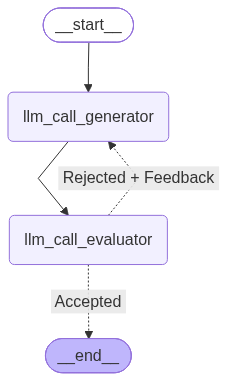

네, 피드백을 반영하여 더 자연스럽고 재미있는 농담을 드리겠습니다.

**농담:**  
Q. 한국에서 사람들이 자주 못 찾는 나라는 어디일까요?  
A. 몰디브(‘몰라, 어디 있지?’와 ‘몰디브’의 언어유희)

**설명:**  
‘몰라, 어디 있지?’라는 흔히 쓰는 말과 실제 나라 이름 ‘몰디브’를 연결하여 언어유희를 자연스럽게 활용했습니다.


In [22]:
# 그래프 구성
optimizer_builder = StateGraph(State)
optimizer_builder.add_node("llm_call_generator", llm_call_generator)
optimizer_builder.add_node("llm_call_evaluator", llm_call_evaluator)

optimizer_builder.add_edge(START, "llm_call_generator")
optimizer_builder.add_edge("llm_call_generator", "llm_call_evaluator")
optimizer_builder.add_conditional_edges(
    "llm_call_evaluator",
    route_joke,
    {
        "Accepted": END,
        "Rejected + Feedback": "llm_call_generator",
    },
)

# 컴파일
optimizer_workflow = optimizer_builder.compile()

# 다이어그램 확인
display(Image(optimizer_workflow.get_graph().draw_mermaid_png()))

# 실행
state = optimizer_workflow.invoke({"topic": "한국"})
print(state["joke"])

In [23]:
# 에이전트 

from langchain_core.tools import tool

@tool
def multiply(a: int, b: int) -> int:
    """두 수를 곱합니다."""
    return a * b

@tool
def add(a: int, b: int) -> int:
    """두 수를 더합니다."""
    return a + b

@tool
def divide(a: int, b: int) -> float:
    """두 수를 나눕니다."""
    return a / b

In [24]:
tools = [add, multiply, divide]
tools_by_name = {tool.name: tool for tool in tools}
llm_with_tools = llm.bind_tools(tools)

from langgraph.graph import MessagesState
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# LLM 호출 노드
def llm_call(state: MessagesState):
    """LLM이 도구 호출 여부를 결정"""
    return {
        "messages": [
            llm_with_tools.invoke(
                [SystemMessage(content="당신은 주어진 입력값으로 산술 연산을 수행하는 유용한 어시스턴트입니다.")]
                + state["messages"]
            )
        ]
    }

In [25]:
# 도구 실행 노드
def tool_node(state: dict):
    """LLM이 요청한 도구를 실행"""
    result = []
    for tool_call in state["messages"][-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))
    return {"messages": result}

In [26]:
# 반복 여부 판단
def should_continue(state: MessagesState) -> Literal["environment", END]:
    """도구 호출이 있으면 계속, 없으면 종료"""
    if state["messages"][-1].tool_calls:
        return "Action"
    return END

In [27]:
# 에이전트 워크플로 구성
agent_builder = StateGraph(MessagesState)
agent_builder.add_node("llm_call", llm_call)
agent_builder.add_node("environment", tool_node)

agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    {"Action": "environment", END: END},
)
agent_builder.add_edge("environment", "llm_call")

agent = agent_builder.compile()

# 실행
messages = [HumanMessage(content="3과 4를 더하세요.")]
messages = agent.invoke({"messages": messages})
for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

3과 4를 더하세요.
================================== Ai Message ==================================
Tool Calls:
  add (call_OKYWI10qD22xnYOJOeGayTJ9)
 Call ID: call_OKYWI10qD22xnYOJOeGayTJ9
  Args:
    a: 3
    b: 4
================================= Tool Message =================================

7
================================== Ai Message ==================================

3과 4를 더하면 7입니다.
